In [8]:
import pandas as pd

In [9]:
df = pd.read_csv("./experiment_results/data/final_results.csv").query("episodes<10")

C:\Users\nande\AppData\Local\Temp\ipykernel_11344\1944275807.py:1: DtypeWarning: Columns (11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("./experiment_results/data/final_results.csv").query("episodes<10")


In [10]:
df["cum_rewards_"] = df.pivot_table(index = ["experiment", "initial_budget", "episodes"], 
                                values = 'rewards', aggfunc = 'cumsum')

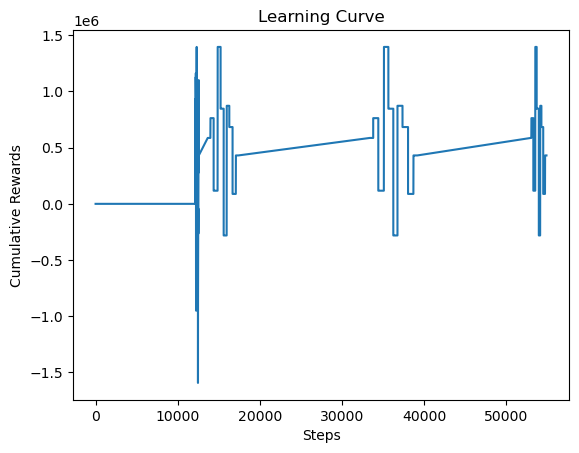

In [11]:
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df['cumulative_rewards'] =  df.groupby('episodes')['rewards'].cumsum()

# Line plot
sns.lineplot(x=df.index, y='cumulative_rewards', data=df)
plt.xlabel('Steps')
plt.ylabel('Cumulative Rewards')
plt.title('Learning Curve')
plt.show()

In [12]:
data = pd.read_parquet("./experiment_results/data/final_results.csv")

ArrowInvalid: Could not open Parquet input source '<Buffer>': Parquet magic bytes not found in footer. Either the file is corrupted or this is not a parquet file.

In [47]:
df.episodes.max()

254

In [52]:
df.query("experiment == 'dqn' and budget == 15_000_000").rewards

33398    0.000000
33932    0.000000
34589    0.000000
34590   -4.686993
34591   -5.432907
35043    0.000000
36189    0.000000
37308    0.000000
37309   -4.655777
37938    0.000000
37939   -4.682990
37940   -5.424071
38472    0.000000
39579    0.000000
39580   -5.397001
39581   -4.317609
40221    0.000000
40222   -4.311078
40223   -4.273438
40766    0.000000
Name: rewards, dtype: float64

In [33]:
import pandas as pd
import plotly.graph_objs as go

def smooth_and_plot_rewards(rewards_series, window_size=10):
    """
    Smooths the cumulative rewards using a rolling window and plots the original and smoothed rewards.

    :param rewards_series: Pandas Series containing cumulative rewards.
    :param window_size: Size of the rolling window for smoothing.
    """
    # Calculate the rolling mean for smoothing
    smoothed_rewards = rewards_series.rolling(window=window_size, min_periods=1).mean()

    # Create the original rewards trace
    original_trace = go.Scatter(
        y=rewards_series,
        mode='lines',
        name='Original Rewards'
    )

    # Create the smoothed rewards trace
    smoothed_trace = go.Scatter(
        y=smoothed_rewards,
        mode='lines',
        name=f'Smoothed Rewards (window={window_size})'
    )

    # Layout settings
    layout = go.Layout(
        title='Cumulative Rewards - Original vs. Smoothed',
        xaxis=dict(title='Episodes'),
        yaxis=dict(title='Cumulative Reward'),
        hovermode='closest'
    )

    # Create the figure and add traces
    fig = go.Figure(data=[original_trace, smoothed_trace], layout=layout)

    # Show the plot
    fig.show()

# Example usage
# Assuming you have a Pandas Series 'cum_rewards_series'
smooth_and_plot_rewards(cum_rewards_series, window_size=10)


NameError: name 'cum_rewards_series' is not defined

In [34]:
df.query("experiment=='dqn'").filter(regex ='episodes|budget|steps|rewards')

,rewards,cum_rewards,budget,initial_budget,steps,episodes,cum_rewards_,cumulative_rewards
12031,0.000000,0.000000,1000000.00,1000000,1,0,0.000000,-26.291095
12032,0.000000,0.000000,954382.84,1000000,2,0,0.000000,-26.291095
12033,1.350104,1.350104,954382.84,1000000,3,0,1.350104,-24.940990
12034,1.034112,2.384216,910263.84,1000000,4,0,2.384216,-23.906879
12035,1.066938,3.451154,910263.84,1000000,5,0,3.451154,-22.839940
...,...,...,...,...,...,...,...,...
51231,-0.011214,74.124503,394659.95,5000000,136,51,74.124503,117.417447
51232,-0.012067,74.112435,394659.95,5000000,137,51,74.112435,117.405380
51233,1.011861,75.124296,354308.87,5000000,138,51,75.124296,118.417241
51234,1.023158,76.147454,354308.87,5000000,139,51,76.147454,119.440399


experiment  initial_budget  episodes
dqn         1000000         0           Axes(0.125,0.11;0.775x0.77)
                            1           Axes(0.125,0.11;0.775x0.77)
                            2           Axes(0.125,0.11;0.775x0.77)
                            3           Axes(0.125,0.11;0.775x0.77)
                            4           Axes(0.125,0.11;0.775x0.77)
                                                   ...             
random      15000000        5           Axes(0.125,0.11;0.775x0.77)
                            6           Axes(0.125,0.11;0.775x0.77)
                            7           Axes(0.125,0.11;0.775x0.77)
                            8           Axes(0.125,0.11;0.775x0.77)
                            9           Axes(0.125,0.11;0.775x0.77)
Name: cum_rewards, Length: 389, dtype: object

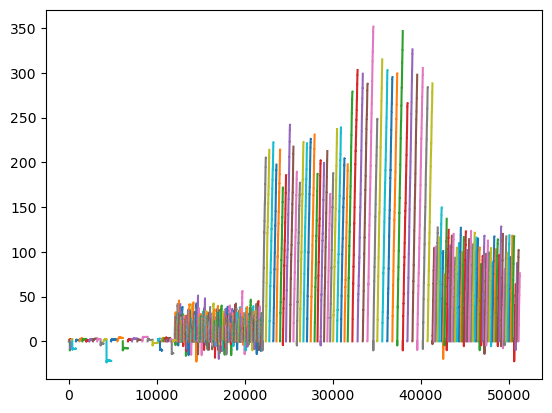

In [35]:
df.groupby(["experiment", "initial_budget", "episodes"]).cum_rewards.plot()